## First calculation with SADKAT: Droplet diameter vs time

Aims to familiarise myself with SADKAT and understand how to run calculations with it.

In [13]:
import sadkat
from sadkat.droplet import UniformDroplet
from sadkat.solutes import aqueous_NaCl
from sadkat.gas import Atmosphere

from dataclasses import dataclass, field
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

import matplotlib as mpl, matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

import chemicals
import os

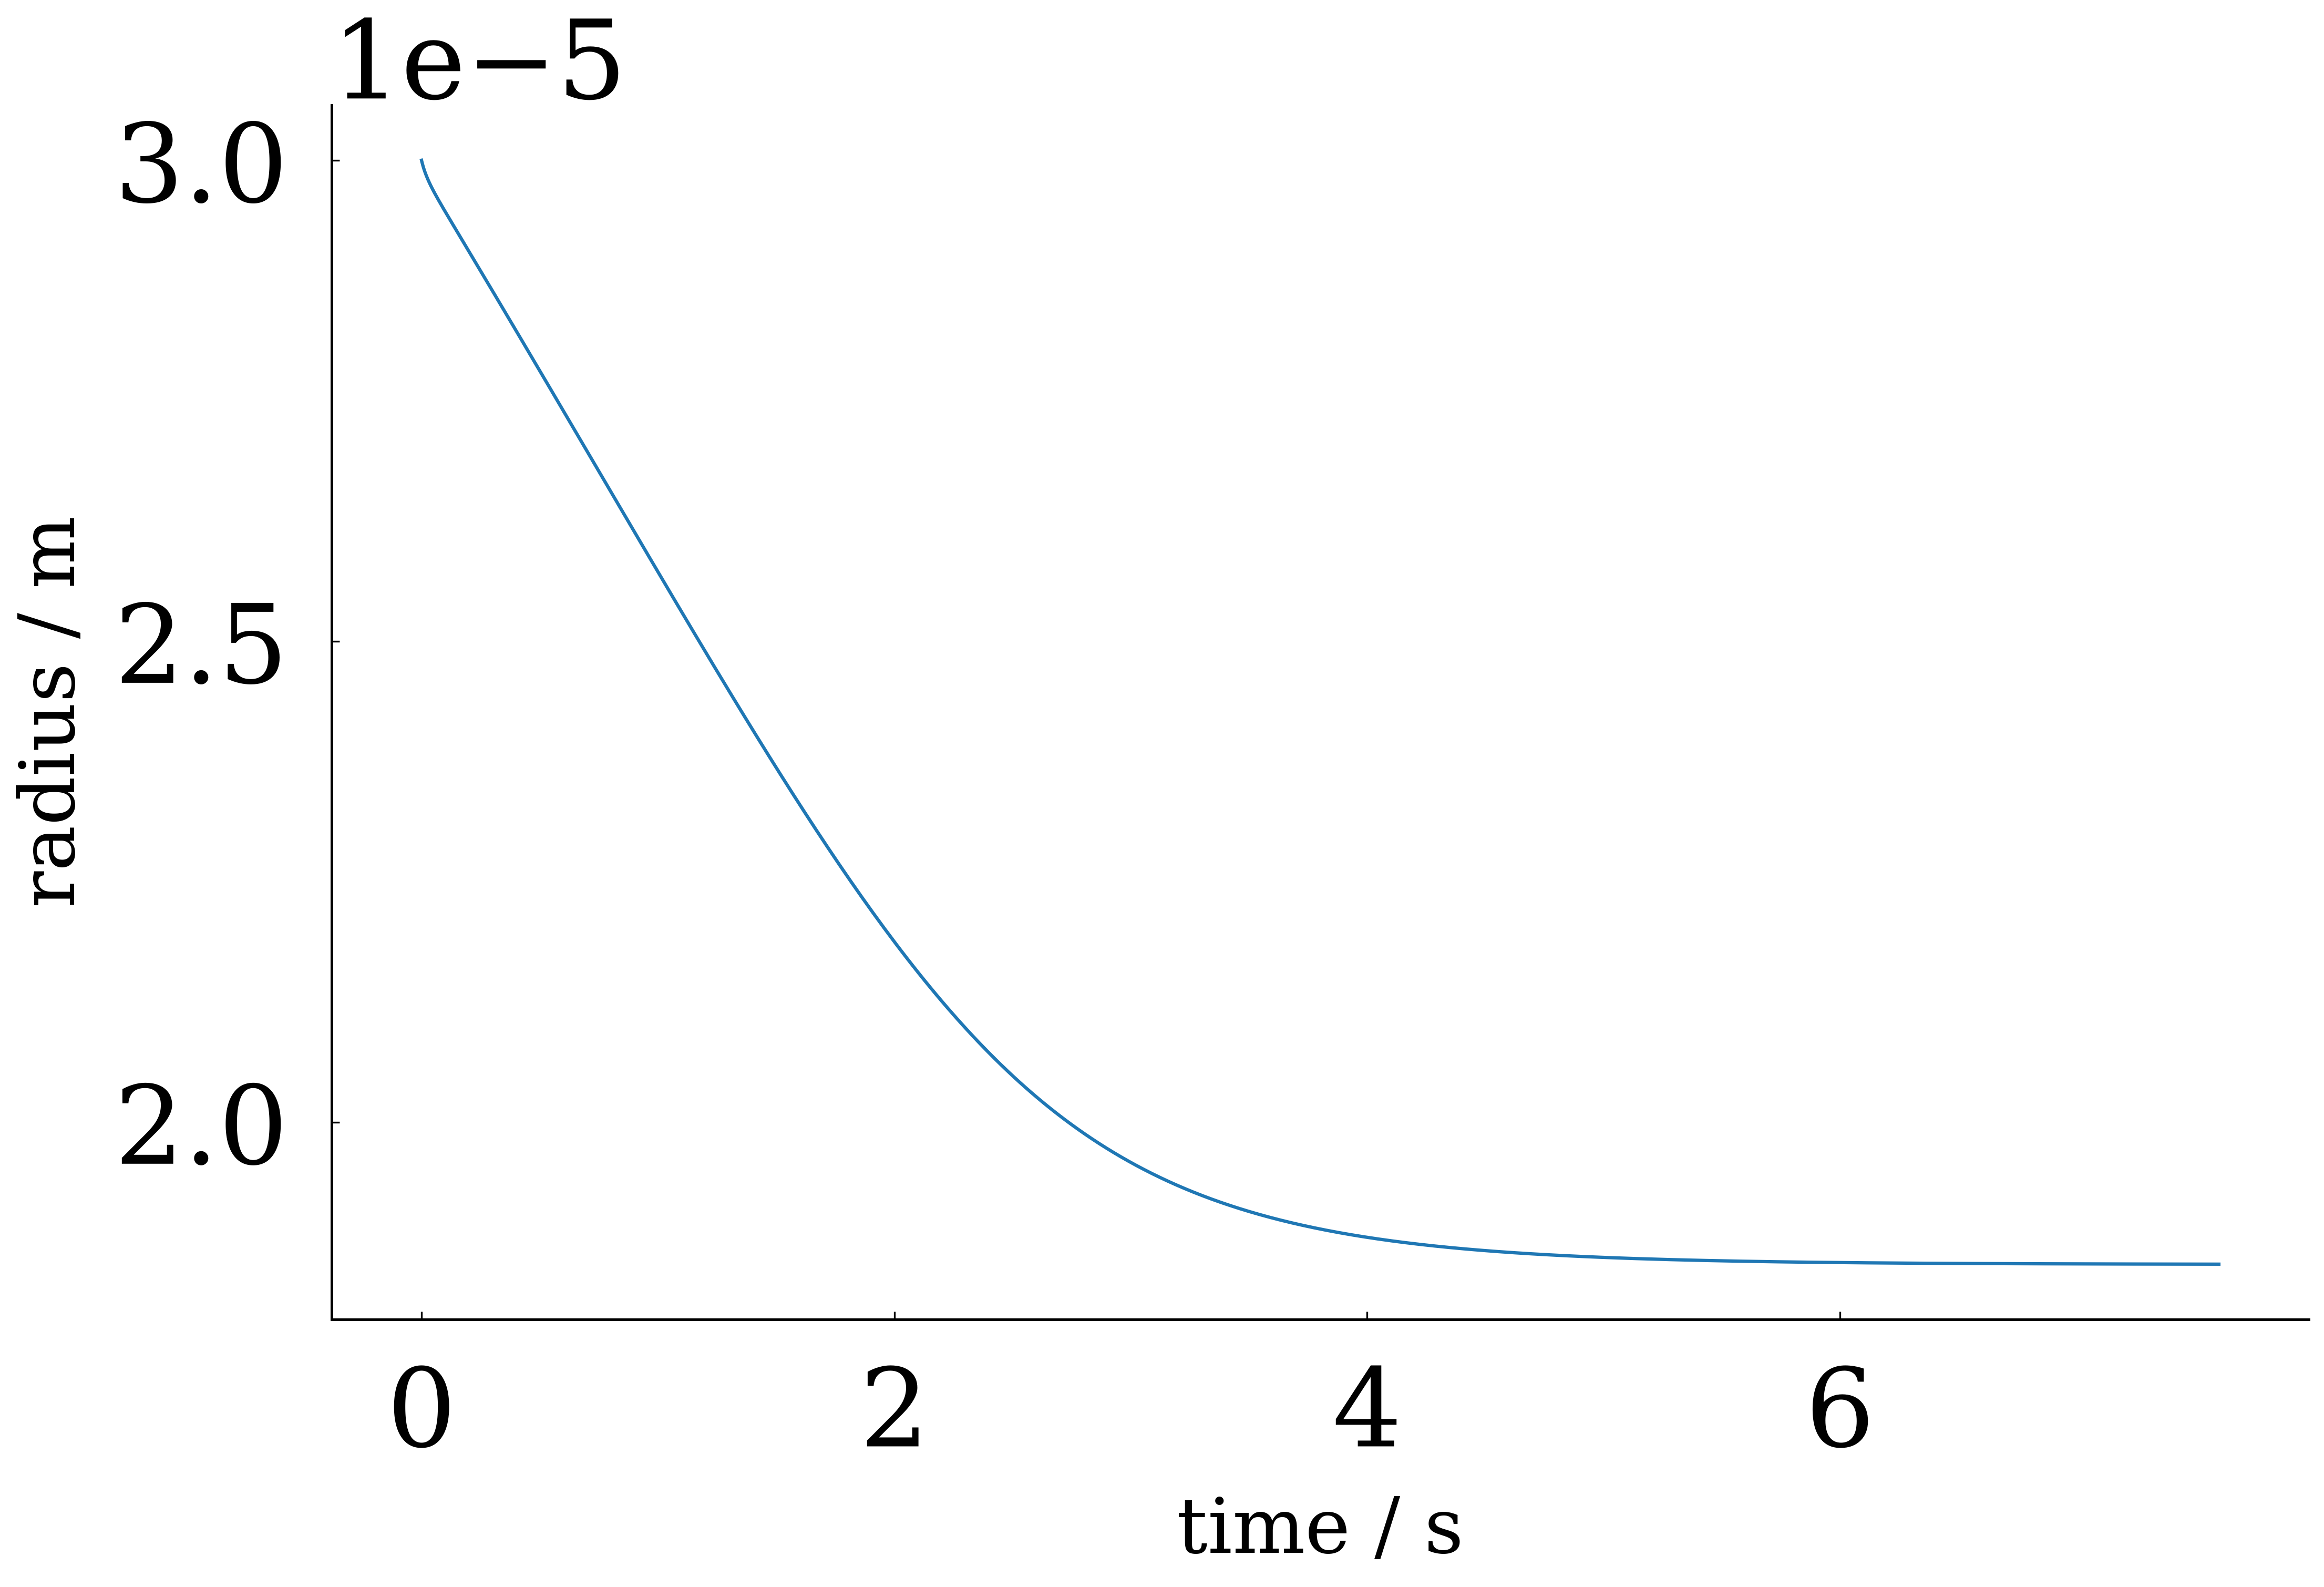

In [14]:
solution = aqueous_NaCl

ambient_temperature = 293 # kelvin
ambient_RH = 0.1
gas = Atmosphere(ambient_temperature, ambient_RH)

gravity = np.zeros(3) # ignore body forces like gravity (representing e.g. EDB setups)
initial_radius = 30e-6 # metres
initial_mfs = 0.2
initial_temperature = 293 # kelvin
initial_velocity = np.zeros(3) # metres/second
initial_position = np.zeros(3) # metres/second
droplet = UniformDroplet.from_mfs(solution,
                                  gas,
                                  gravity,
                                  initial_radius,
                                  initial_mfs,
                                  initial_temperature,
                                  initial_velocity,
                                  initial_position)

time = 100 # seconds
trajectory = droplet.integrate(time, terminate_on_equilibration=True)
# Obtain a table giving a history of *all* droplet parameters.
history = droplet.complete_trajectory(trajectory)

plt.plot(history['time'], history['radius'])
plt.xlabel('time / s')
plt.ylabel('radius / m')
plt.show()

In [16]:
print(history.head())
print(history.columns)
print(history.dtypes)

           mass   mass_solute  mass_solvent  mass_fraction_solute  \
0  1.297444e-10  2.594889e-11  1.037956e-10                   0.2   
1  1.297444e-10  2.594889e-11  1.037956e-10                   0.2   
2  1.297444e-10  2.594889e-11  1.037956e-10                   0.2   
3  1.297444e-10  2.594889e-11  1.037956e-10                   0.2   
4  1.297444e-10  2.594889e-11  1.037956e-10                   0.2   

   mass_fraction_solvent  mole_fraction_solute  mole_fraction_solvent  \
0                    0.8              0.071553               0.928447   
1                    0.8              0.071553               0.928447   
2                    0.8              0.071553               0.928447   
3                    0.8              0.071553               0.928447   
4                    0.8              0.071553               0.928447   

       density   radius  vapour_pressure  ...   vy   vz  speed    x    y    z  \
0  1147.192759  0.00003      1945.171918  ...  0.0  0.0    0.0  0

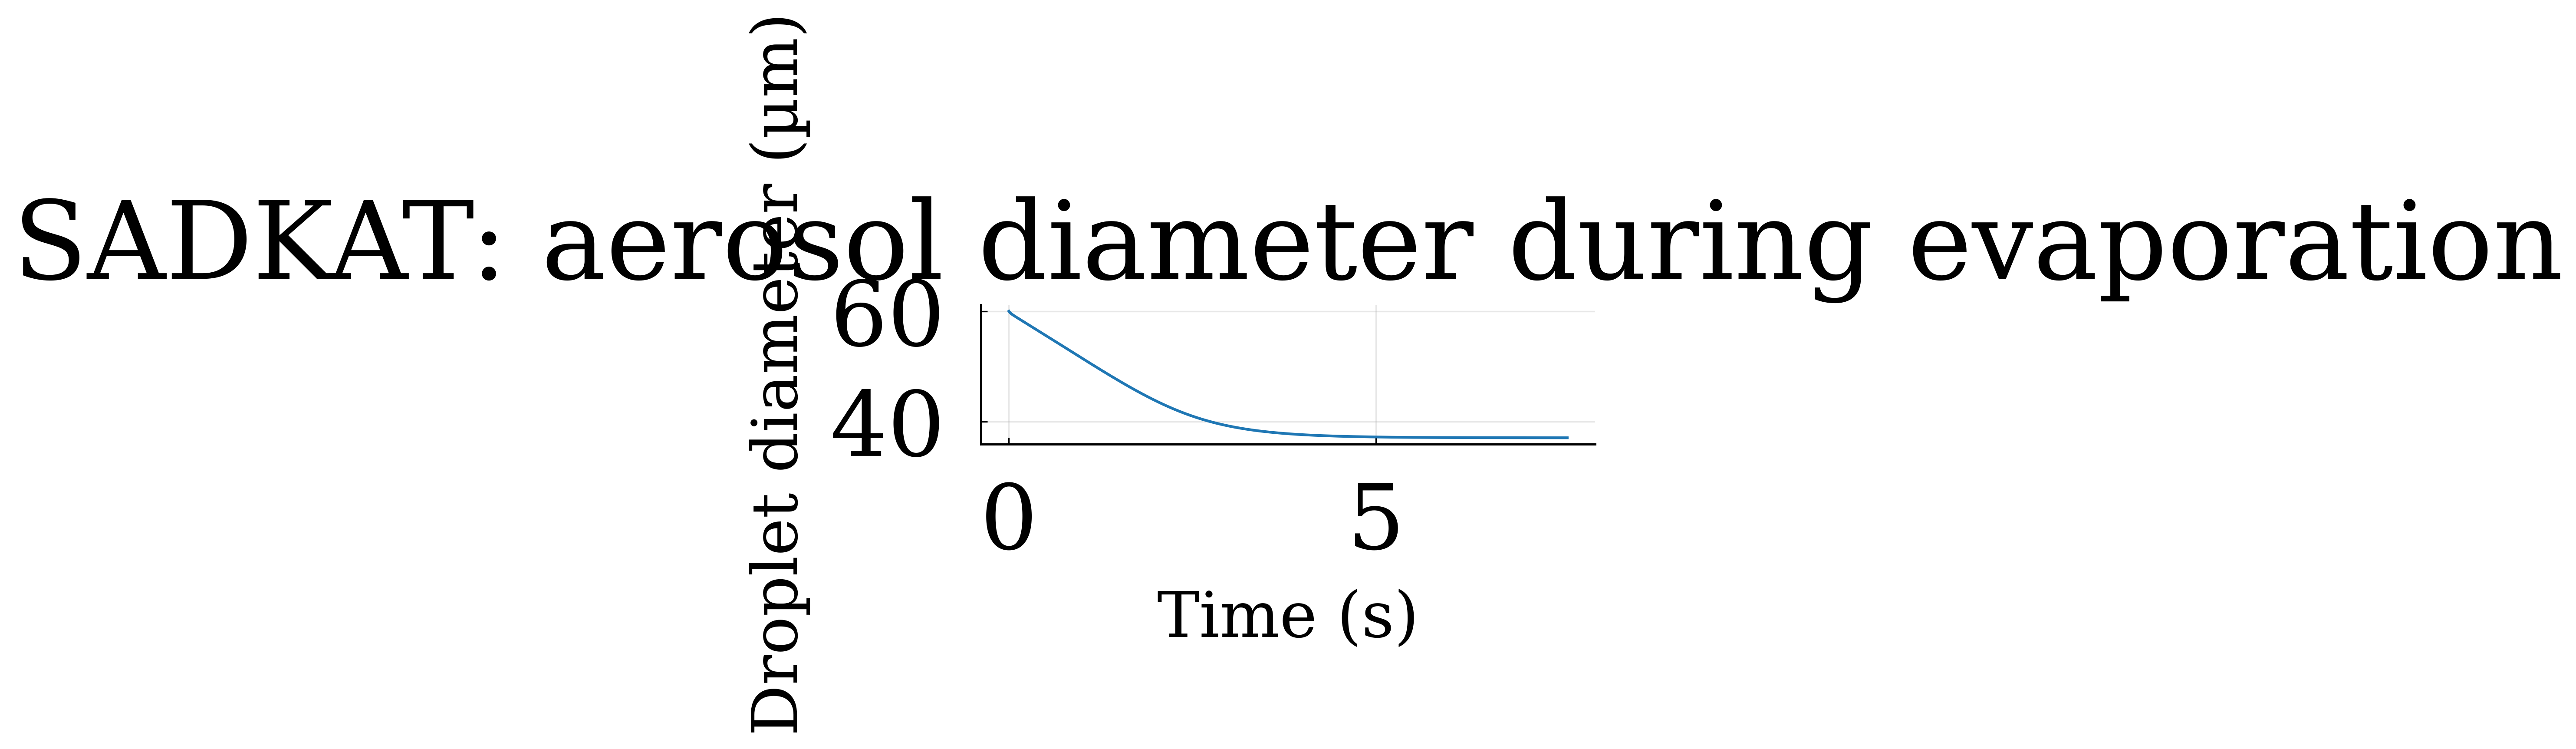

In [18]:
# Replace these names with the actual column names.
time_s = history["time"]
radius_m = history["radius"]

diameter_um = 2 * radius_m * 1e6

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(time_s, diameter_um)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Droplet diameter (µm)")
ax.set_title("SADKAT: aerosol diameter during evaporation")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
initial_diameter = diameter_um.iloc[0]
final_diameter = diameter_um.iloc[-1]

percentage_decrease = (
    (initial_diameter - final_diameter)
    / initial_diameter * 100
)

print(f"Initial diameter: {initial_diameter:.3f} µm")
print(f"Final diameter:   {final_diameter:.3f} µm")
print(f"Diameter decrease: {percentage_decrease:.1f}%")

Initial diameter: 60.000 µm
Final diameter:   37.047 µm
Diameter decrease: 38.3%


Observations:
Initially droplet shrinks quickly, and then more slowly as it reaches an equilibrium point (non-zero, so the droplet does not disappear).
Questions:
What physical process is causing this shrink, and how is it being implemented.

## How does relative humidity affect aerosol drying kinetics?

Experimenting with the model now that it is working. I will loop over relative humidity of the environment and explore how this affects the plot.

In [ ]:
solution = aqueous_NaCl

ambient_temperature = 293 # kelvin
ambient_RH = 0.1
gas = Atmosphere(ambient_temperature, ambient_RH)

gravity = np.zeros(3) # ignore body forces like gravity (representing e.g. EDB setups)
initial_radius = 30e-6 # metres
initial_mfs = 0.2
initial_temperature = 293 # kelvin
initial_velocity = np.zeros(3) # metres/second
initial_position = np.zeros(3) # metres/second

droplet = UniformDroplet.from_mfs(solution,
                                  gas,
                                  gravity,
                                  initial_radius,
                                  initial_mfs,
                                  initial_temperature,
                                  initial_velocity,
                                  initial_position)

time = 100 # seconds
trajectory = droplet.integrate(time, terminate_on_equilibration=True)
# Obtain a table giving a history of *all* droplet parameters.
history = droplet.complete_trajectory(trajectory)

plt.plot(history['time'], history['radius'])
plt.xlabel('time / s')
plt.ylabel('radius / m')
plt.show()

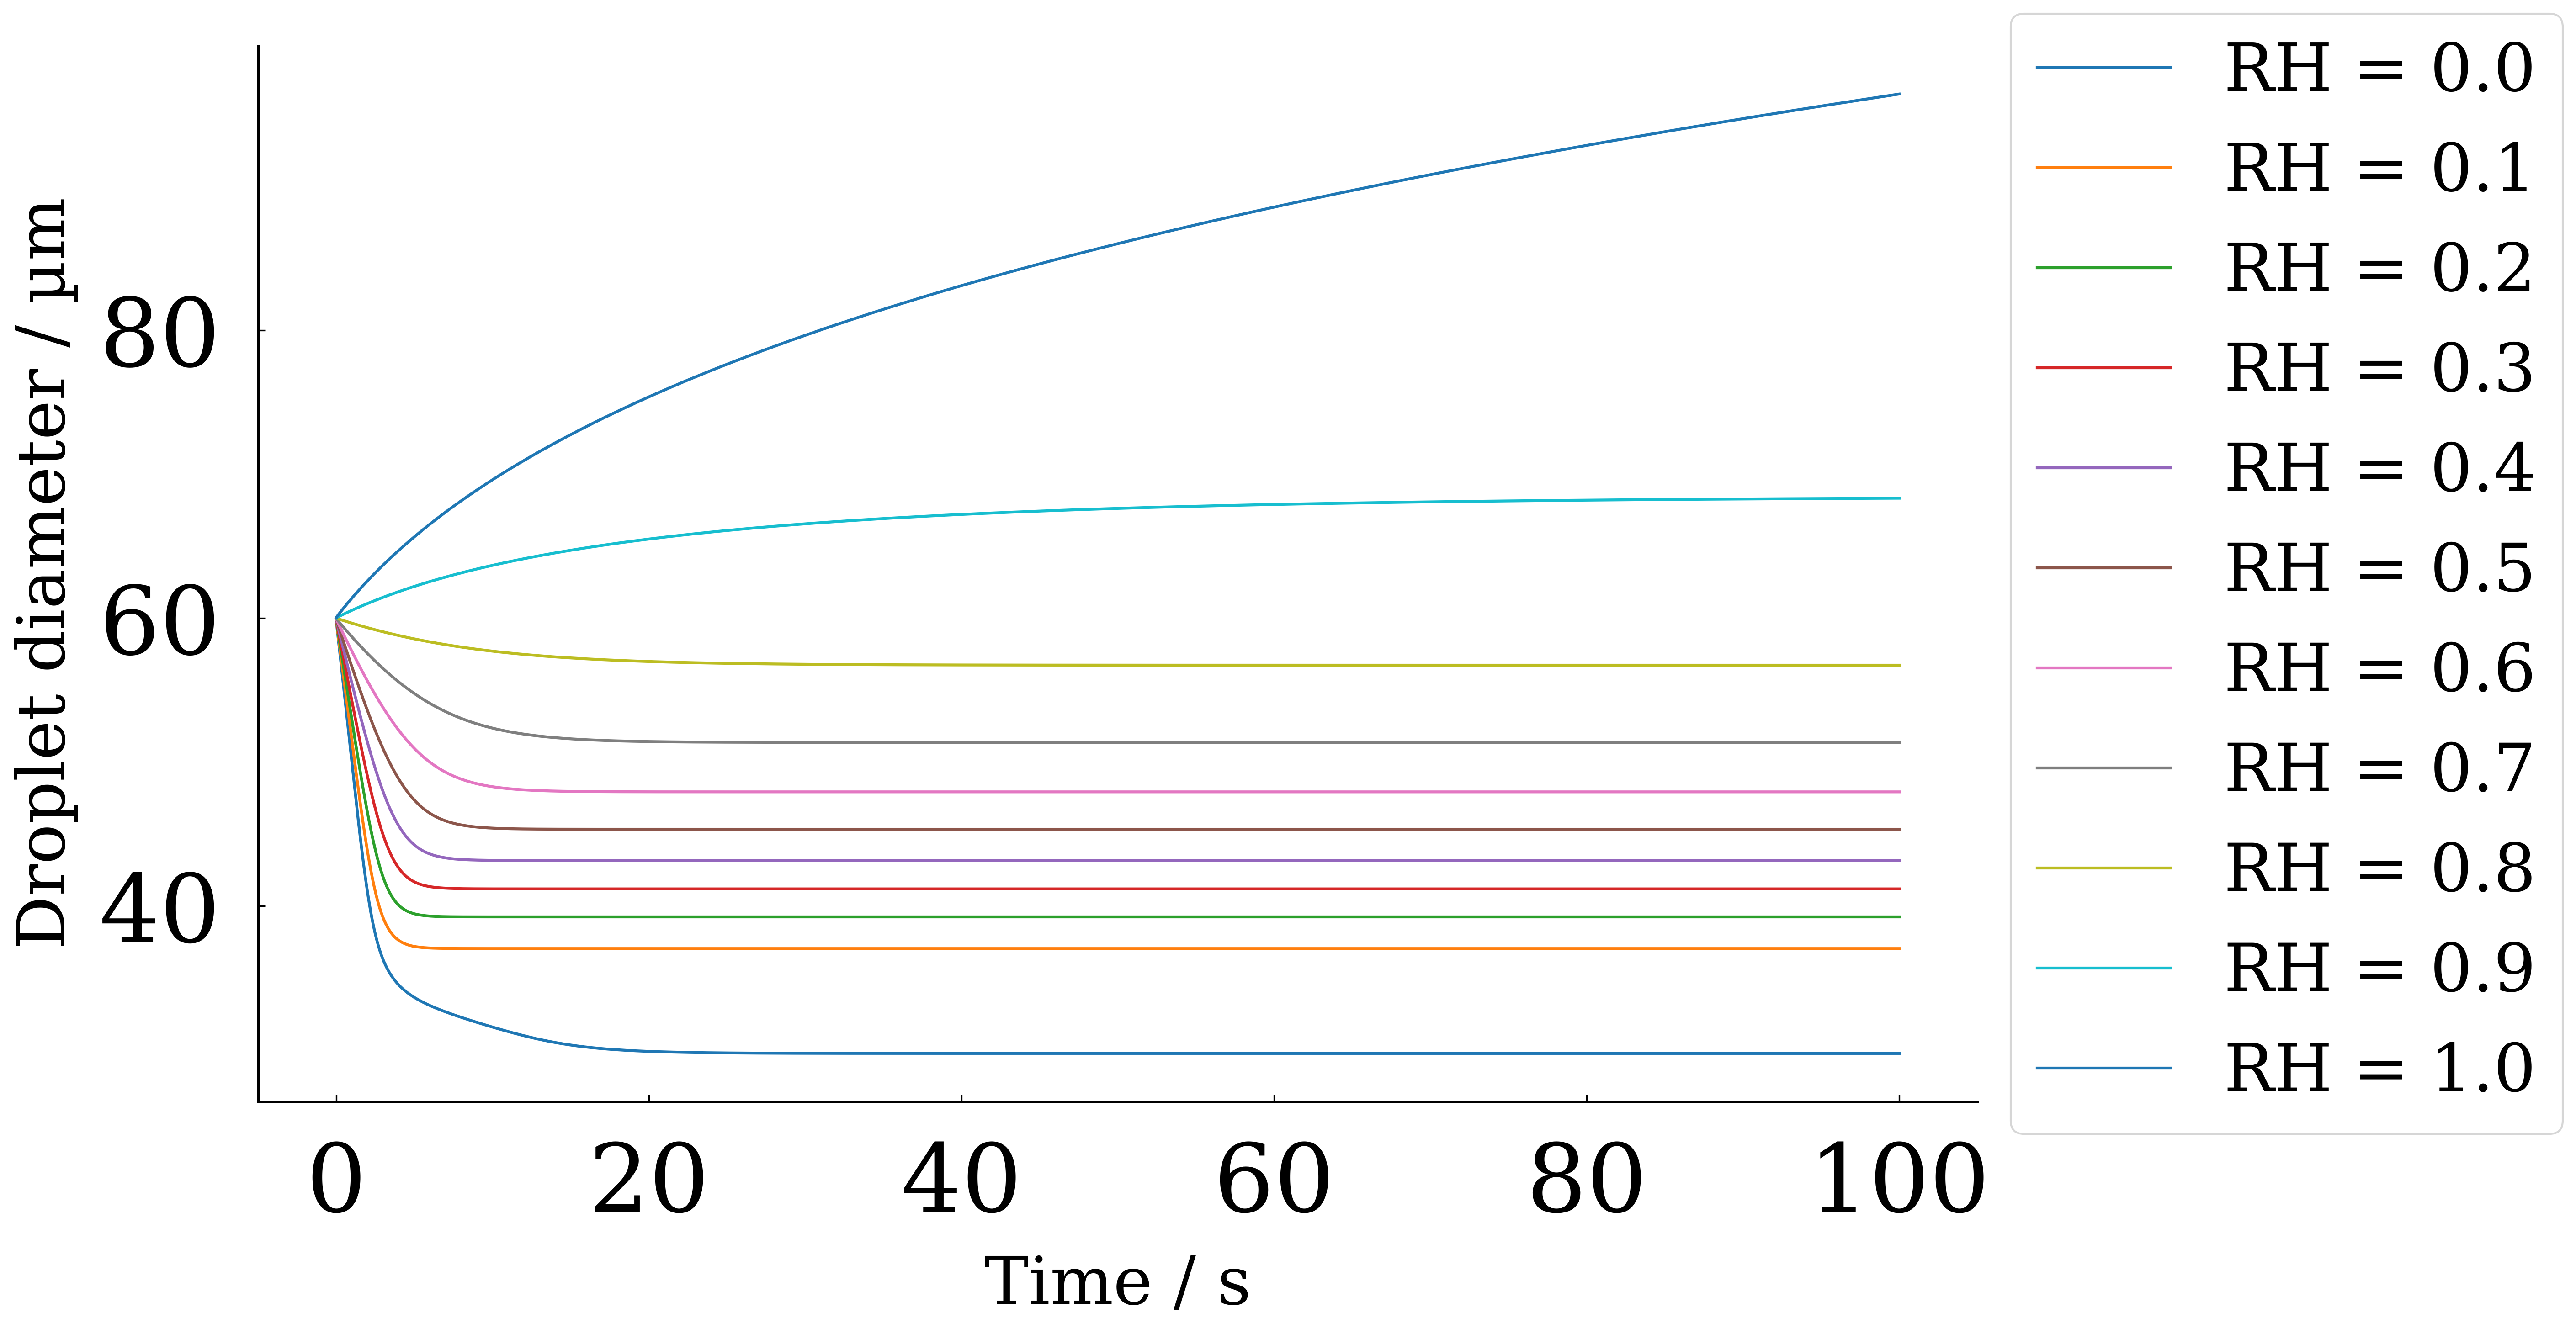

In [22]:
for ambient_RH in np.arange(0.0, 1.01, 0.1):
    # Create the atmosphere and droplet
    gas = Atmosphere(293, ambient_RH)

    # Run the simulation
    droplet = UniformDroplet.from_mfs(
        solution, gas, gravity, initial_radius,
        initial_mfs, initial_temperature,
        initial_velocity, initial_position
    )

    trajectory = droplet.integrate(
        100, terminate_on_equilibration=False
    )
    history = droplet.complete_trajectory(trajectory)

    # Add this simulation to the graph
    plt.plot(
        history["time"],
        history["radius"] * 2e6,
        label=f"RH = {ambient_RH:.1f}"
    )

plt.xlabel("Time / s")
plt.ylabel("Droplet diameter / µm")
# plt.legend()

# # Shrink current axis by 20%
# box = ax.get_position()
# ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])

# Put a legend to the right of the current axis
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.show()

Increasing relative humidity leads to an greater equilibrium radius.
